# C · Comparison — who is worse, and when?

Three comparisons, each normalised so it is fair:

1. **Year on year** — Jul–Dec 2019 against what the 2018-trained baseline expected (weather-normalised), next to the raw change.
2. **Floor vs floor** — the shape KPIs from A plus the cooling slope from B, ranked.
3. **Zone vs zone** — overcooling league table across the building.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
from sbanalytics import baseline as B, kpis as K, config as C, analysis as A

In [2]:
h = D.load_hourly(None)
fh = B.floor_hourly(h)
fd = B.floor_daily(fh)
OFFICE = [2, 3, 4, 5, 6, 7]     # F1 has no AC schedule (eda/00 §5): excluded from schedule-based measures

## 1 · Year on year, weather-normalised

The baseline is trained on Jul 2018 – Jun 2019 and predicts Jul–Dec 2019 from that period's weather and calendar. *Normalised change* = (actual − expected) / expected. The raw change compares mean kWh per usable day in the same months of 2018 and 2019, restricted to months where both years have data.

In [3]:
_, pred = B.fit_hourly_ladder(fh, "total_kwh")
t = B.split(pred, ("2019-07-01", "2019-12-31")).dropna(subset=["total_kwh"])
norm = t.groupby("floor").apply(lambda g: g.total_kwh.sum() / g.TOWT.sum() - 1, include_groups=False).rename("normalised change (TOWT)")

d = fd[fd.ok & fd.day.dt.month.ge(7)].assign(year=lambda x: x.day.dt.year, month=lambda x: x.day.dt.month)
m = d.groupby(["floor", "month", "year"]).total_kwh.mean().unstack("year").dropna()
raw = (m[2019].groupby("floor").sum() / m[2018].groupby("floor").sum() - 1).rename("raw change, matched months")
months = m.groupby("floor").size().rename("months compared")

w = D.load_weather().assign(month=lambda x: x.ts.dt.month, year=lambda x: x.ts.dt.year)
cdd = (w[w.month >= 7].assign(c=lambda x: (x.out_temp - 24).clip(lower=0) / 24).groupby("year").c.sum())
print(f"Jul–Dec cooling degree-days (base 24 °C): 2018 {cdd[2018]:.0f}, 2019 {cdd[2019]:.0f}")

chosen = pd.read_csv(C.DATA_DERIVED / "baseline_chosen.csv").query("target == 'total_kwh'").set_index("floor").meets_g14
yoy = pd.concat([raw, months, norm, chosen.rename("baseline meets G14")], axis=1)
yoy.style.format({"raw change, matched months": "{:+.1%}", "normalised change (TOWT)": "{:+.1%}"})

Jul–Dec cooling degree-days (base 24 °C): 2018 659, 2019 734


,"raw change, matched months",months compared,normalised change (TOWT),baseline meets G14
floor,,,,
1,-15.5%,6,-12.2%,False
2,-0.6%,6,-1.2%,True
3,-3.1%,6,-2.2%,True
4,+4.9%,6,+3.5%,True
5,+2.5%,6,+0.9%,True
6,+1.7%,4,+1.9%,True
7,+2.4%,6,+0.4%,True


Read the normalised change only where the baseline meets G14; elsewhere it is indicative. Jul–Dec 2019 includes F6 only until 22 Oct.

## 2 · Floor benchmark

Rank 1 = best. Lower is better for every KPI here.

In [4]:
kpi = pd.read_csv(C.DATA_DERIVED / "floor_kpis.csv", index_col="floor")
cp = pd.read_csv(C.DATA_DERIVED / "changepoint_params.csv").query("regime == 'workday'").set_index("floor")
bench = kpi.loc[[2, 3, 4, 5, 6, 7], ["baseload_ratio", "after_hours_ac_share", "overcooled_share"]].copy()
bench["cooling_slope_pct_per_c"] = (cp.kwh_per_day_per_c / kpi.workday_kwh_per_day * 100).loc[bench.index]
ranks = bench.rank().astype(int).add_suffix(" rank")
bench = bench.join(ranks)
bench["mean rank"] = ranks.mean(axis=1)
bench = bench.sort_values("mean rank")
bench.style.background_gradient(cmap="Blues", subset=[c for c in bench.columns if c.endswith("rank")]).format(precision=2)

,baseload_ratio,after_hours_ac_share,overcooled_share,cooling_slope_pct_per_c,baseload_ratio rank,after_hours_ac_share rank,overcooled_share rank,cooling_slope_pct_per_c rank,mean rank
floor,,,,,,,,,
3,0.01,0.05,0.80,4.99,2,3,3,2,2.50
5,0.01,0.01,0.68,5.88,3,1,1,5,2.50
4,0.01,0.05,0.82,3.01,5,2,5,1,3.25
6,0.01,0.06,0.75,5.10,4,4,2,3,3.25
7,0.01,0.12,0.83,7.04,1,5,6,6,4.50
2,0.08,0.28,0.80,5.16,6,6,4,4,5.00


`cooling_slope_pct_per_c` = extra workday energy per °C of outdoor temperature above the balance point, as a % of a typical workday — how weather-sensitive each floor is, comparable across floor sizes.

## 3 · Zone league table — overcooling

Occupied, cooled, sensor-valid hours. `cold_degree_hours` sums how far below 23 °C each zone was held; dividing by AC energy in the same hours gives an intensity comparable between zones of different size.

In [5]:
z = K.zone_comfort(h)
z["cold_dh_per_mwh"] = z.cold_degree_hours / (z.ac_kwh_in_window / 1000)
z = z.sort_values("cold_dh_per_mwh", ascending=False)
z[["floor", "zone", "hours", "mean_temp_c", "share_below_lo", "cold_degree_hours", "cold_dh_per_mwh", "share_rh_above"]].round(2)

,floor,zone,hours,mean_temp_c,share_below_lo,cold_degree_hours,cold_dh_per_mwh,share_rh_above
2,2,z4,1748,18.55,1.00,7784.48,522.48,0.99
6,3,z5,1582,20.23,0.98,4401.31,350.99,0.96
10,4,z5,1918,21.56,0.79,3223.77,211.30,0.83
5,3,z4,1876,19.47,0.97,6660.10,200.47,0.92
9,4,z4,1584,20.07,0.92,4830.50,157.56,0.53
8,4,z2,1888,21.10,0.80,3869.17,135.41,1.00
17,6,z5,1587,22.74,0.73,1171.56,124.79,0.53
12,5,z4,2093,21.64,0.72,3793.91,120.20,0.98
13,5,z5,2192,22.82,0.65,1832.16,116.91,0.95
21,7,z5,1886,22.38,0.67,2024.83,103.17,0.53


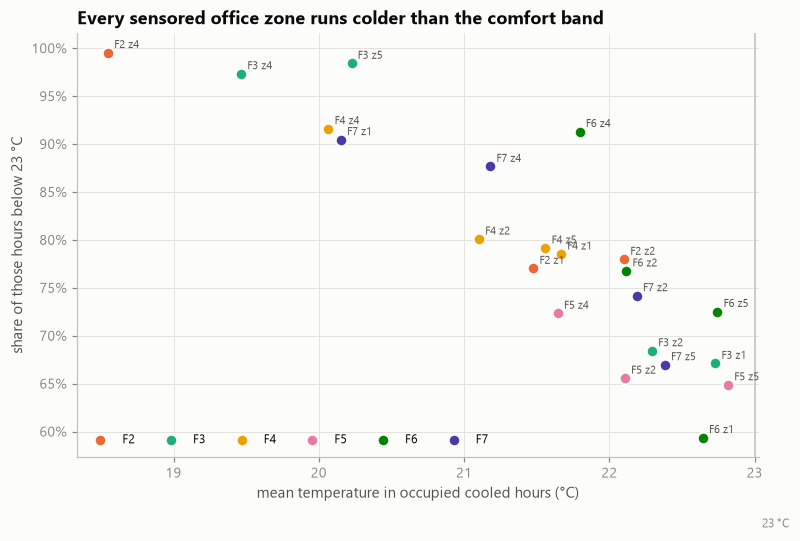

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
for f, g in z.groupby("floor"):
    ax.scatter(g.mean_temp_c, g.share_below_lo, s=60, color=viz.FLOOR_COLORS[f], edgecolor=viz.SURFACE, linewidth=1.5, label=f"F{f}")
    for _, r in g.iterrows():
        ax.annotate(f"F{f} {r.zone}", (r.mean_temp_c, r.share_below_lo), xytext=(4, 3), textcoords="offset points", fontsize=7, color=viz.INK_2)
ax.axvline(23, color=viz.AXIS, lw=1); ax.text(23.05, 0.5, "23 °C", color=viz.MUTED, fontsize=8)
ax.set_xlabel("mean temperature in occupied cooled hours (°C)"); ax.set_ylabel("share of those hours below 23 °C")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_title("Every sensored office zone runs colder than the comfort band")
ax.legend(ncol=6, fontsize=8, loc="lower left")